
## Course work 2

## Machine Learning

### By Manas Prasun Pandey (A00014692)


Summary of Steps:
1. Import required libraries for CNN
2. Load and Preprocess images
3. Split Data into training and test data
4. View Sample Training and Test Data
5. Build the model
6. Evaluate the Model
7. Metrics for the CNN Model
8. Test with new Alert and Drowsy sample.
9. Real time Detection
10. Enhancements
11. Key Points
12. Summary of the Model

### 1. Import required libraries for CNN

In [4]:
# import libraries needed
import os
import time
from datetime import datetime
import cv2
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import Precision, Recall, AUC
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
print("Libraries Loaded... @ ",datetime.now())

Libraries Loaded... @  2024-12-03 22:04:52.845564


In [5]:
print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.18.0
GPU Available: []


In [6]:
# Parameters
IMG_SIZE = 128  # Image resolution
BATCH_SIZE = 32
EPOCHS = 10
print("Image Size: ",IMG_SIZE)
print("Batch size: ",BATCH_SIZE)
print("EPOCHs: ",EPOCHS)

Image Size:  128
Batch size:  32
EPOCHs:  10


### 2. Load and Preprocess images

In [8]:
# Load images and labels
def load_data(data_dir):
    images = []
    labels = []
    categories = ["Alert", "Drowsy"]  # Assuming directories are named "alert" and "drowsy"
    for label, category in enumerate(categories):
        category_path = os.path.join(data_dir, category)
        for img_name in os.listdir(category_path):
            img_path = os.path.join(category_path, img_name)
            img = cv2.imread(img_path)
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))  # Resize
            images.append(img / 255.0)  # Normalize
            labels.append(label)
    return np.array(images), np.array(labels)
print("Pre-processing Image data... @ ",datetime.now())

Pre-processing Image data... @  2024-12-03 22:04:52.934034


In [9]:
# Load data
data_dir = "Dataset2K/" #path to dataset
images, labels = load_data(data_dir)
print("Image data loaded... @ ",datetime.now())

Image data loaded... @  2024-12-03 22:05:22.555321


### 3. Split Data into training and test data

In [11]:
# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(images, labels, test_size=0.2, random_state=42)
print("Train-Test split done... @ ",datetime.now())

Train-Test split done... @  2024-12-03 22:05:22.960927


### 4. View Sample Training and Test Data

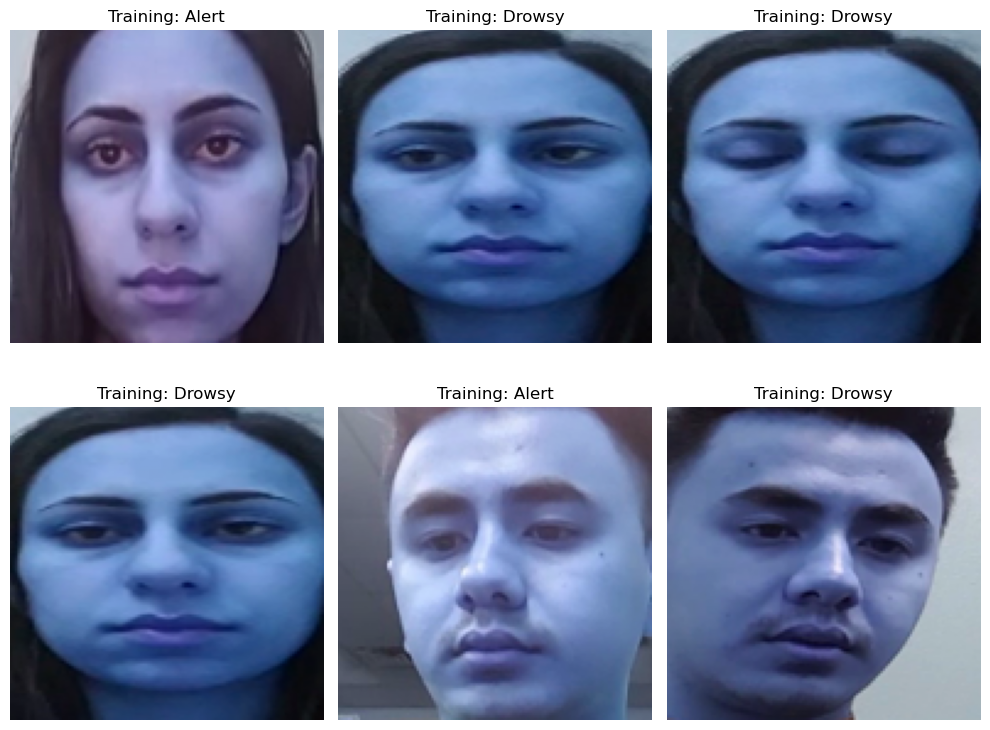

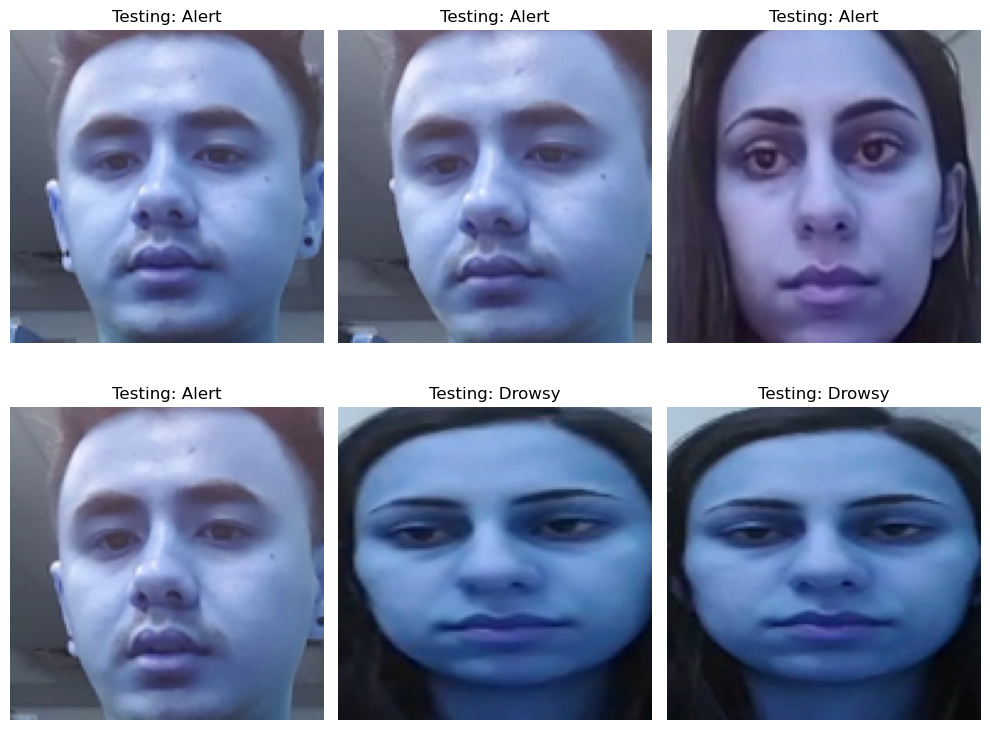

In [13]:
#Visualize data from Training and sample
import matplotlib.pyplot as plt

# Function to display sample images
def plot_sample_images(X, y, title, categories=['Alert', 'Drowsy']):
    plt.figure(figsize=(10, 8))
    for i in range(6):
        plt.subplot(2, 3, i + 1)
        plt.imshow(X[i])
        plt.title(f"{title}: {categories[y[i]]}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()

# Display samples from training, test, and validation datasets
plot_sample_images(X_train, y_train, title="Training")
plot_sample_images(X_test, y_test, title="Testing")


### 5. Build the model

In [15]:
# Define the CNN model
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(2, activation='softmax')  # 2 classes: alert and drowsy
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

C:\Users\manas\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 2)                   │             258 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,304,898 (12.61 MB)

 Trainable params: 3,304,898 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Train the model
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)

Epoch 1/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 11s 203ms/step - accuracy: 0.7520 - loss: 0.4785 - val_accuracy: 1.0000 - val_loss: 3.3403e-06
Epoch 2/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 177ms/step - accuracy: 1.0000 - loss: 7.7401e-04 - val_accuracy: 1.0000 - val_loss: 9.9263e-05
Epoch 3/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 194ms/step - accuracy: 0.9805 - loss: 0.1223 - val_accuracy: 1.0000 - val_loss: 0.0014
Epoch 4/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 199ms/step - accuracy: 0.9988 - loss: 0.0112 - val_accuracy: 1.0000 - val_loss: 3.3321e-05
Epoch 5/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 193ms/step - accuracy: 1.0000 - loss: 2.7402e-04 - val_accuracy: 1.0000 - val_loss: 6.8120e-08
Epoch 6/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 198ms/step - accuracy: 0.9992 - loss: 0.0023 - val_accuracy: 1.0000 - val_loss: 8.6470e-06
Epoch 7/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 202ms/step - accuracy: 1.0000 - loss: 1.8054e-04 - val_accuracy: 1.0000 - val_loss: 2.4343e-06
Epoch 8/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 9s 246ms/step - accuracy: 1.0

In [17]:
print("Model Training completed... @ ",datetime.now())

Model Training completed... @  2024-12-03 22:06:45.253221


### 6. Evaluate the Model

In [19]:
# Evaluate on test data
results = model.evaluate(X_test, y_test)
print("Test Results:", results)

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 1.0000 - loss: 3.7238e-07
Test Results: [3.2342319400413544e-07, 1.0]


### 7. Metrics for the CNN Model

In [21]:
y_pred = np.argmax(model.predict(X_test), axis=1)
# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Alert', 'Drowsy']))

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step
Classification Report:
              precision    recall  f1-score   support

       Alert       1.00      1.00      1.00       216
      Drowsy       1.00      1.00      1.00       143

    accuracy                           1.00       359
   macro avg       1.00      1.00      1.00       359
weighted avg       1.00      1.00      1.00       359



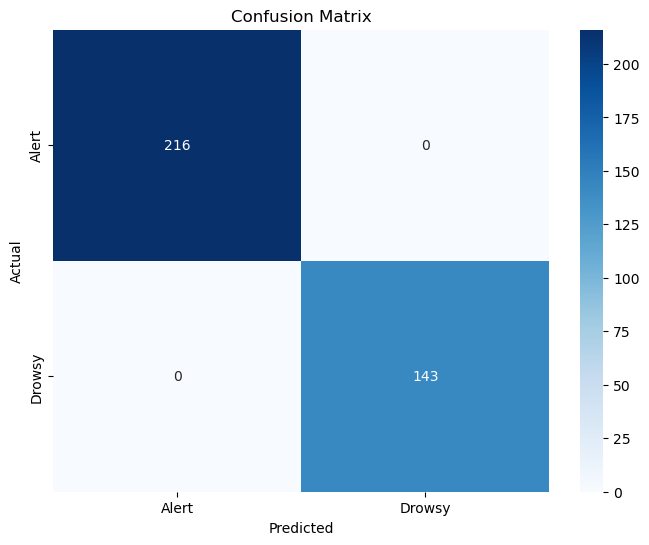

In [22]:
# Plot the confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=['Alert', 'Drowsy'], yticklabels=['Alert', 'Drowsy'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

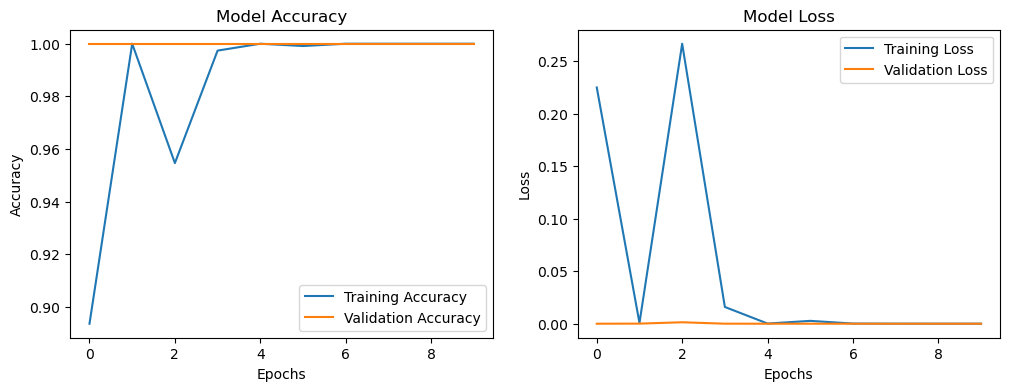

In [23]:
# Plot accuracy and loss
plt. figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Model Accuracy')

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Model Loss')

plt.show()

### 8. Test with new Alert and Drowsy sample.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Predicted Class: Drowsy


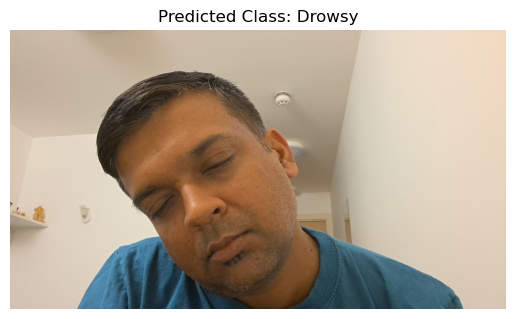

In [25]:
def preprocess_image(image_path, img_size):
    """
    Preprocess the image for the model and return the preprocessed image and the original image for display.
    """
    img = cv2.imread(image_path)  # Load the image
    if img is None:
        raise FileNotFoundError(f"Image not found at {image_path}")
    original_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert to RGB for display
    img = cv2.resize(img, (img_size, img_size))  # Resize to match model input
    img = img / 255.0  # Normalize pixel values
    img = np.expand_dims(img, axis=0)  # Add batch dimension
    return img, original_img  # Return preprocessed and original image



# Preprocess the image
def test_random_sample(image_path):
    sample_image, original_image = preprocess_image(image_path, IMG_SIZE)
    predictions = model.predict(sample_image)
    predicted_class = np.argmax(predictions, axis=1)[0]
    class_names = ['Alert', 'Drowsy']  # Update with your class labels
    print(f"Predicted Class: {class_names[predicted_class]}")
    plt.imshow(original_image)
    plt.title(f"Predicted Class: {class_names[predicted_class]}")
    plt.axis('off')  # Hide axes for better display
    plt.show()

# Path to a sample drowsy image
sample_image_path = "test/drowsy_me.jpg"
test_random_sample(sample_image_path)

### 9. Real time Detection

In [ ]:
def real_time_detection(model):
    cap = cv2.VideoCapture(0)  # Open webcam
    start_time = time.time()  # Track the start time

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # Check if 1 second has passed
        if time.time() - start_time >= 1:
            start_time = time.time()  # Reset start time

            # Preprocess the frame
            img = cv2.resize(frame, (IMG_SIZE, IMG_SIZE))
            img = img / 255.0
            img = np.expand_dims(img, axis=0)

            # Predict state
            prediction = model.predict(img)
            state = "Alert" if np.argmax(prediction) == 0 else "Drowsy"

            # Display the result
            cv2.putText(frame, f"State: {state}", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)
            cv2.imshow("Driver State Detection", frame)

        # Press 'q' to exit
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()

# Run real-time detection by uncommenting line below
real_time_detection(model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━

### 10. Enhancements
Data Augmentation: Add random rotations, flips, and brightness adjustments to improve model robustness.

Transfer Learning: Use pre-trained models (e.g., MobileNet, ResNet) for better accuracy with fewer training samples.

Blink Detection: Combine with blink detection algorithms for additional features.

Multi-modal Input: Use additional data (e.g., head pose or eye-tracking data).

### 11. Key Features of the Model
##### Input Shape:

The input shape is (IMG_SIZE, IMG_SIZE, 3), meaning it expects images of size IMG_SIZE x IMG_SIZE with 3 color channels (RGB).
Layers:

##### Convolutional Layers:
Three Conv2D layers with 32, 64, and 128 filters respectively, each using a kernel size of (3, 3) and ReLU activation.
These layers extract features such as edges, textures, and patterns from the images.
##### MaxPooling Layers:
MaxPooling2D layers after each convolutional layer with a pool size of (2, 2) to reduce spatial dimensions, which decreases computational load and helps in retaining important features.
##### Fully Connected Layers:
A Flatten layer converts the 2D feature maps into a 1D feature vector for the dense layers.
A Dense layer with 128 neurons and ReLU activation for learning high-level patterns.
A Dropout layer with a rate of 0.5 to reduce overfitting.
A final Dense layer with 2 neurons (corresponding to 2 classes: "alert" and "drowsy") and softmax activation for classification.
##### Output:

The softmax activation in the final layer outputs probabilities for the two classes (alert and drowsy).
##### Loss Function:

The model uses sparse_categorical_crossentropy as the loss function, which is suitable for classification tasks where the labels are integers (0 and 1 in this case).
##### Optimizer:

The Adam optimizer is used for efficient training and adaptive learning rates.
##### Metrics:

Accuracy, Precision, Recall and F1 is used as the evaluation metric.
Confusion Metrics shows TP FP FN FP

### 12. Summary of the Model
- It is a CNN designed for binary image classification (e.g., "alert" vs. "drowsy").
- The architecture is compact and suitable for relatively small datasets.
- Dropout is included to mitigate overfitting.